<a href="https://colab.research.google.com/github/TiTKi1/-ML/blob/main/%D0%9B%D0%A0_10_%D0%9C%D0%B0%D0%BC%D0%B5%D0%B4%D0%BE%D0%B2_3_9_ipynb%22.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Лабораторна робота № 10
## Побудова нейронної мережі засобами Keras. Налаштування гіперпараметрів

**Прізвище, ім’я:** Мамедов Руслан Ільгарович
**Група:** ФІТ 3-9
**Дата:** 19.11.2026

**Мета:** навчитися завантажувати та готувати дані Fashion MNIST, створювати і навчати нейронну мережу засобами Keras, оцінювати якість класифікації, а також підбирати гіперпараметри за допомогою Keras Tuner.

**Порядок виконання:** послідовно виконайте кожен пункт у наведених комірках. Доповніть код, збережіть графіки та результати виконання, сформулюйте власні висновки.

### Вхідні дані та критерії

Використовуйте **Fashion MNIST** — зображення розміром **28 × 28 пікселів** із **10 класів**.  
У **завданні 1** цільова точність на тестовій вибірці — **не нижче 0,87** (відповідно до вихідної лабораторної роботи).

**Важливо:** тестова вибірка призначена для фінального оцінювання. Для навчання, ранньої зупинки та добору гіперпараметрів використовуйте окрему валідаційну частину навчальних даних; не налаштовуйте модель за результатами тестової вибірки.

## Підготовка робочого середовища

Імпортуйте необхідні бібліотеки. У другому завданні буде потрібно встановити та підключити **Keras Tuner**.

In [1]:
# Підготуйте імпорти TensorFlow / Keras, NumPy, Matplotlib,
# classification_report, а також потрібних callback-функцій.
# Ваш код:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.metrics import classification_report
print("TensorFlow version:", tf.__version__)


TensorFlow version: 2.21.0


# Завдання 1. Класифікація Fashion MNIST за допомогою Keras

### Крок 1. Завантаження даних

Завантажте Fashion MNIST. Створіть навчальну й тестову вибірки та перелік назв **10 класів**. Виведіть розміри масивів даних.

In [2]:
# Завантажте Fashion MNIST, визначте class_names.
# Виведіть форми x_train, y_train, x_test, y_test.
(x_train, y_train), (x_test, y_test) = keras.datasets.fashion_mnist.load_data()
class_names = ["T-shirt/top", "Trouser", "Pullover", "Dress", "Coat", "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"]
print("x_train:", x_train.shape, "y_train:", y_train.shape)
print("x_test:", x_test.shape, "y_test:", y_test.shape)
# Ваш код:


29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
x_train: (60000, 28, 28) y_train: (60000,)
x_test: (10000, 28, 28) y_test: (10000,)


### Крок 2. Візуальний аналіз

Виведіть **10 зображень** навчальної вибірки. Для кожного підпишіть відповідний клас.

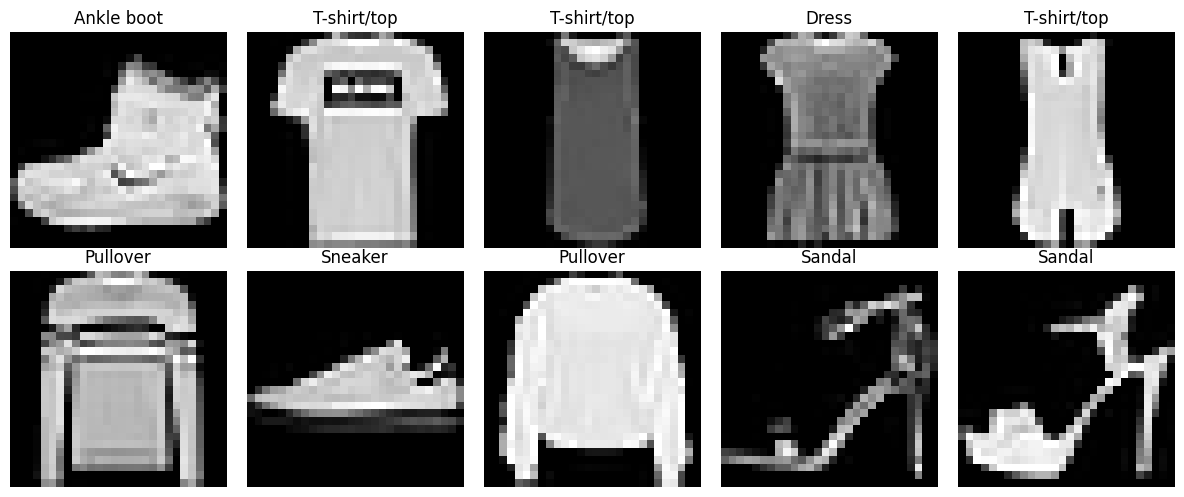

In [3]:
# Побудуйте візуалізацію 10 зображень із підписами класів.
# Ваш код:
plt.figure(figsize=(12, 5))
for i in range(10):
  plt.subplot(2, 5, i + 1)
  plt.imshow(x_train[i], cmap="gray")
  plt.title(class_names[y_train[i]])
  plt.axis("off")
plt.tight_layout()
plt.show()


### Крок 3. Нормалізація

Нормалізуйте значення пікселів до діапазону **[0; 1]**. Переконайтеся, що тип даних придатний для навчання нейронної мережі.

In [4]:
# Нормалізуйте навчальні й тестові дані.
# Перевірте діапазони значень.
x_train = x_train.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0
print("x_train min/max:", x_train.min(), x_train.max(), x_train.dtype)
# Ваш код:


x_train min/max: 0.0 1.0 float32


### Крок 4. Побудова й компіляція моделі

Створіть послідовну нейронну мережу. Використайте перетворення зображення у вектор, повнозв’язні шари з **ReLU**, регуляризацію **Dropout** та вихід із **10 нейронів із softmax**. Налаштуйте оптимізатор Adam, функцію втрат для багатокласової класифікації з цілочисельними мітками та метрику accuracy.

Поясніть вибір кількості нейронів, dropout і швидкості навчання.

In [5]:
# Створіть і скомпілюйте модель.
# Ваш код:
model = keras.Sequential([layers.Flatten(input_shape=(28, 28), name="flatten"), layers.Dense(256, activation="relu", name="dense_256"), layers.Dropout(0.3, name="dropout_1"), layers.Dense(128, activation="relu", name="dense_128"), layers.Dropout(0.3, name="dropout_2"), layers.Dense(10, activation="softmax", name="output")], name="fashion_mnist_mlp")
learning_rate = 0.001
model.compile(optimizer=keras.optimizers.Adam(learning_rate=learning_rate), loss=keras.losses.SparseCategoricalCrossentropy(), metrics=["accuracy"])
model.summary()


/usr/local/lib/python3.13/dist-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "fashion_mnist_mlp"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_256 (Dense)               │ (None, 256)            │       200,960 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_128 (Dense)               │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output (Dense)                  │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 235,146 (918.54 KB)

 Trainable params: 235,146 (918.54 KB)

 Non-trainable params: 0 (0.00 B)

### Крок 5. Навчання моделі

Навчіть модель із виділенням **валідаційної частини з навчальної вибірки**. Застосуйте **EarlyStopping** і **ReduceLROnPlateau**. Збережіть історію навчання для подальших графіків.

In [6]:
# Налаштуйте callbacks і навчіть модель.
# Збережіть history.
early_stopping = keras.callbacks.EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True)
reduce_lr = keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2, min_lr=1e-6)
history = model.fit(x_train, y_train, validation_split=0.2, epochs=30, batch_size=64, callbacks=[early_stopping, reduce_lr], verbose=1)
# Ваш код:


Epoch 1/30
750/750 ━━━━━━━━━━━━━━━━━━━━ 8s 8ms/step - accuracy: 0.7822 - loss: 0.6114 - val_accuracy: 0.8417 - val_loss: 0.4324 - learning_rate: 0.0010
Epoch 2/30
750/750 ━━━━━━━━━━━━━━━━━━━━ 8s 10ms/step - accuracy: 0.8394 - loss: 0.4439 - val_accuracy: 0.8575 - val_loss: 0.3854 - learning_rate: 0.0010
Epoch 3/30
750/750 ━━━━━━━━━━━━━━━━━━━━ 6s 8ms/step - accuracy: 0.8503 - loss: 0.4072 - val_accuracy: 0.8666 - val_loss: 0.3687 - learning_rate: 0.0010
Epoch 4/30
750/750 ━━━━━━━━━━━━━━━━━━━━ 7s 10ms/step - accuracy: 0.8605 - loss: 0.3829 - val_accuracy: 0.8701 - val_loss: 0.3566 - learning_rate: 0.0010
Epoch 5/30
750/750 ━━━━━━━━━━━━━━━━━━━━ 6s 8ms/step - accuracy: 0.8659 - loss: 0.3656 - val_accuracy: 0.8752 - val_loss: 0.3468 - learning_rate: 0.0010
Epoch 6/30
750/750 ━━━━━━━━━━━━━━━━━━━━ 7s 10ms/step - accuracy: 0.8716 - loss: 0.3495 - val_accuracy: 0.8752 - val_loss: 0.3387 - learning_rate: 0.0010
Epoch 7/30
750/750 ━━━━━━━━━━━━━━━━━━━━ 9s 8ms/step - accuracy: 0.8738 - loss: 0.3394

### Крок 6. Аналіз архітектури

Виведіть підсумкову структуру нейронної мережі, кількість шарів і параметрів.

In [7]:
# Виведіть підсумок архітектури моделі.
# Ваш код:
model.summary()
print("Кількість шарів:", len(model.layers))
print("Кількість параметрів:", model.count_params())


Model: "fashion_mnist_mlp"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_256 (Dense)               │ (None, 256)            │       200,960 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_128 (Dense)               │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output (Dense)                  │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 705,440 (2.69 MB)

 Trainable params: 235,146 (918.54 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 470,294 (1.79 MB)

Кількість шарів: 6
Кількість параметрів: 235146


### Крок 7. Збереження моделі

Збережіть навчену модель у форматі **`.keras`**. Під час роботи в Google Colab за потреби підключіть Google Drive.

In [8]:
# Збережіть навчену модель (.keras).
# За потреби підключіть Google Drive.
# Ваш код:

model.save("fashion_mnist_model.keras")
print("Модель збережено у форматі .keras")

Модель збережено у форматі .keras


### Крок 8. Графіки навчання

Побудуйте два графіки: **функція втрат (loss)** і **точність (accuracy)** для навчальної та валідаційної вибірок. Підпишіть осі, легенди й назви графіків.

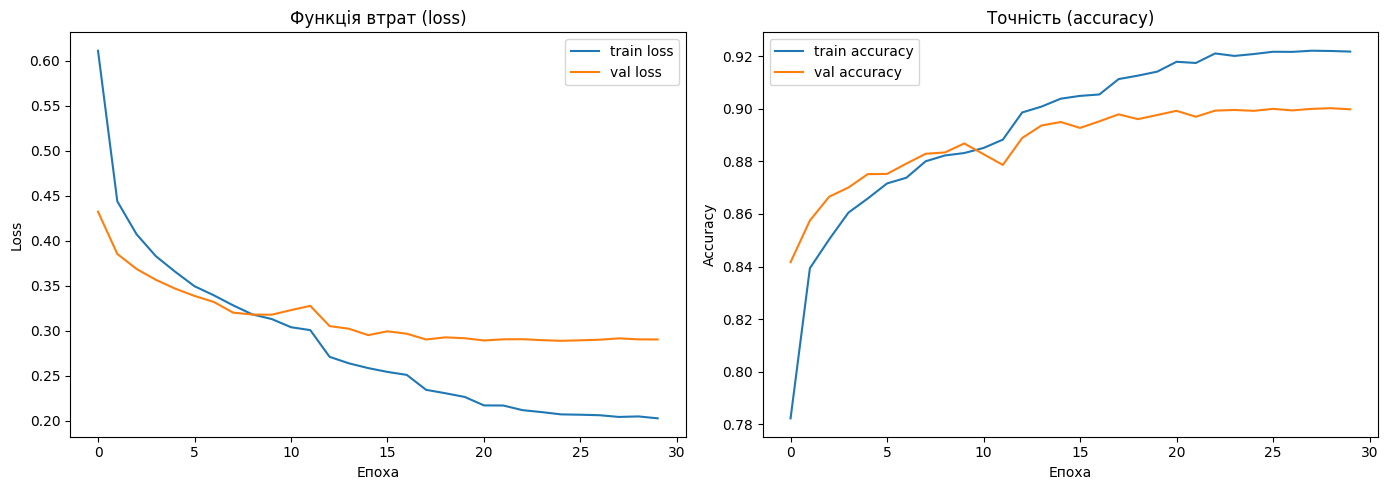

In [9]:
# Побудуйте графіки loss/val_loss та accuracy/val_accuracy.
# Ваш код:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].plot(history.history["loss"], label="train loss")
axes[0].plot(history.history["val_loss"], label="val loss")
axes[0].set_title("Функція втрат (loss)")
axes[0].set_xlabel("Епоха")
axes[0].set_ylabel("Loss")
axes[0].legend()
axes[1].plot(history.history["accuracy"], label="train accuracy")
axes[1].plot(history.history["val_accuracy"], label="val accuracy")
axes[1].set_title("Точність (accuracy)")
axes[1].set_xlabel("Епоха")
axes[1].set_ylabel("Accuracy")
axes[1].legend()
plt.tight_layout()
plt.show()


### Крок 9. Оцінювання моделі

Один раз оцініть навчену модель на **тестовій вибірці**. Отримайте прогнози й сформуйте **класифікаційний звіт** (precision, recall, F1-score) для всіх класів.

Порівняйте отриману accuracy з порогом **0,87**.

In [10]:
# Обчисліть loss і accuracy на тестовій вибірці.
# Знайдіть прогнозовані класи та сформуйте classification_report.
test_loss, test_accuracy = model.evaluate(x_test, y_test, verbose=0)
probabilities = model.predict(x_test, verbose=0)
predicted_classes = np.argmax(probabilities, axis=1)
print(f"Тестова accuracy: {test_accuracy:.4f}")
print(f"Тестова loss: {test_loss:.4f}")
print("Виконано вимогу щодо accuracy >= 0.87:", test_accuracy >= 0.87)
print(classification_report(y_test, predicted_classes, target_names=class_names))
# Ваш код:


Тестова accuracy: 0.8933
Тестова loss: 0.3110
Виконано вимогу щодо accuracy >= 0.87: True
              precision    recall  f1-score   support

 T-shirt/top       0.85      0.85      0.85      1000
     Trouser       0.98      0.97      0.98      1000
    Pullover       0.81      0.81      0.81      1000
       Dress       0.89      0.91      0.90      1000
        Coat       0.80      0.82      0.81      1000
      Sandal       0.98      0.97      0.97      1000
       Shirt       0.73      0.70      0.71      1000
     Sneaker       0.95      0.97      0.96      1000
         Bag       0.98      0.98      0.98      1000
  Ankle boot       0.97      0.96      0.96      1000

    accuracy                           0.89     10000
   macro avg       0.89      0.89      0.89     10000
weighted avg       0.89      0.89      0.89     10000



### Крок 10. Візуалізація прогнозів

Покажіть **10 тестових зображень**. Для кожного вкажіть правильний і прогнозований клас, а правильність прогнозу позначте кольором підпису.

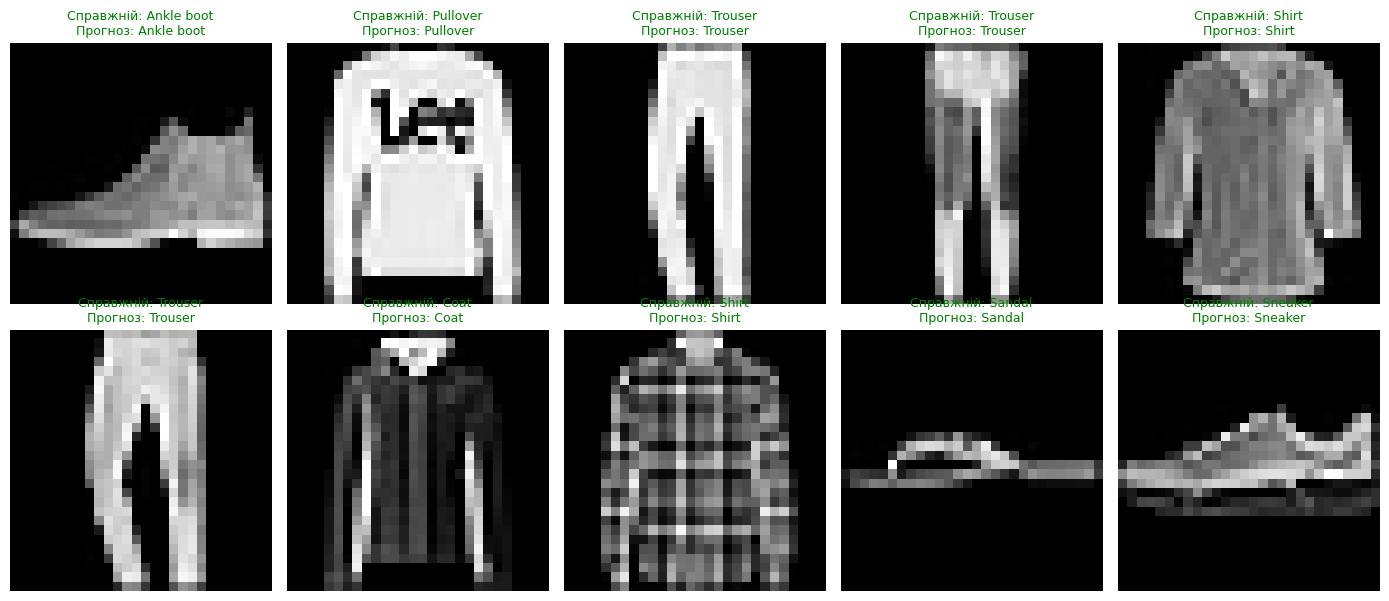

In [11]:
# Візуалізуйте 10 зображень: справжні й прогнозовані класи.
# Ваш код:
plt.figure(figsize=(14, 6))
for i in range(10):
  plt.subplot(2, 5, i + 1)
  plt.imshow(x_test[i], cmap="gray")
  true_label = class_names[y_test[i]]
  pred_label = class_names[predicted_classes[i]]
  color = "green" if pred_label == true_label else "red"
  plt.title(f"Справжній: {true_label}\nПрогноз: {pred_label}", color=color, fontsize=9)
  plt.axis("off")
plt.tight_layout()
plt.show()


**Проміжний висновок до завдання 1**

Запишіть значення тестової accuracy, охарактеризуйте класи з найбільшою кількістю помилок та поясніть, чи виконано вимогу щодо мінімальної точності.

**Ваш висновок:**  
Тестова accuracy моделі з завдання 1 становить 0.8933 (loss 0.3110), що перевищує мінімальний поріг 0.87, вказаний у завданні. Найбільше помилок класифікатор допускає для класу Shirt (precision 0.73, recall 0.70) — ці зображення часто плутаються з класами T-shirt/top, Pullover і Coat через схожу форму верхнього одягу без рукавів чи з коротким рукавом. Клас Trouser, навпаки, розпізнається майже ідеально (precision і recall 0.97-0.98), оскільки штани мають чітку видовжену форму, яка слабко перетинається з іншими класами. Отже, вимогу щодо мінімальної точності (не нижче 0.87) виконано.

# Завдання 2. Добір гіперпараметрів за допомогою Keras Tuner

На основі того самого набору даних виконайте автоматизований пошук конфігурації нейронної мережі. У вихідній лабораторній роботі використовується **RandomSearch**.

### Крок 1. Підготовка Keras Tuner

Установіть `keras-tuner` (за потреби) й імпортуйте засоби для пошуку гіперпараметрів, шари Dense, Flatten, Dropout та регуляризацію L2.

In [12]:
# За потреби встановіть keras-tuner.
# Імпортуйте RandomSearch та потрібні компоненти Keras.
# Ваш код:
!pip install -q keras-tuner
import keras_tuner as kt
from tensorflow.keras.regularizers import l2
print("Keras Tuner version:", kt.__version__)


Keras Tuner version: 1.4.8


### Крок 2. Підготовка набору даних

Повторно використайте Fashion MNIST у нормалізованому вигляді. Переконайтеся, що вибірка для **валідації відокремлена від тестової**. Не передавайте `x_test`, `y_test` у процес пошуку гіперпараметрів.

In [13]:
# Підготуйте дані для добору гіперпараметрів і фінального тестування.
# Ваш код:
from sklearn.model_selection import train_test_split
x_train_tune, x_val_tune, y_train_tune, y_val_tune = train_test_split(x_train, y_train, test_size=0.2, random_state=42)
print("x_train_tune:", x_train_tune.shape, "x_val_tune:", x_val_tune.shape)


x_train_tune: (48000, 28, 28) x_val_tune: (12000, 28, 28)


### Крок 3. Функція побудови моделі

Реалізуйте функцію, яка приймає набір гіперпараметрів та повертає скомпільовану модель. Передбачте пошук **кількості прихованих шарів (1–3)**, **кількості нейронів (32–512 із кроком 32)** та **швидкості навчання (0,01; 0,001; 0,0001)**. Використайте ReLU, Dropout, L2 та softmax, як у вихідному варіанті лабораторної роботи.

In [14]:
# Опишіть функцію build_model(hp).
# Задайте області пошуку гіперпараметрів.
def build_model(hp):
  model = keras.Sequential()
  model.add(layers.Flatten(input_shape=(28, 28)))
  num_layers = hp.Int("num_layers", 1, 3)
  for i in range(num_layers):
    units = hp.Int(f"units_{i}", min_value=32, max_value=512, step=32)
    model.add(layers.Dense(units, activation="relu", kernel_regularizer=l2(1e-4)))
    model.add(layers.Dropout(0.3))
  model.add(layers.Dense(10, activation="softmax"))
  hp_learning_rate = hp.Choice("learning_rate", values=[0.01, 0.001, 0.0001])
  model.compile(optimizer=keras.optimizers.Adam(learning_rate=hp_learning_rate), loss=keras.losses.SparseCategoricalCrossentropy(), metrics=["accuracy"])
  return model
# Ваш код:


### Крок 4. Налаштування пошуку

Створіть **RandomSearch** з критерієм **val_accuracy**. У вихідному прикладі передбачено **3 спроби (max_trials = 3)** і **1 виконання на спробу**. Зазначте каталог збереження результатів пошуку.

In [15]:
# Ініціалізуйте RandomSearch.
# Ваш код:
tuner = kt.RandomSearch(build_model, objective="val_accuracy", max_trials=3, executions_per_trial=1, directory="kt_dir", project_name="fashion_mnist_tuning", overwrite=True)
tuner.search_space_summary()


Search space summary
Default search space size: 3
num_layers (Int)
{'default': None, 'conditions': [], 'min_value': 1, 'max_value': 3, 'step': 1, 'sampling': 'linear'}
units_0 (Int)
{'default': None, 'conditions': [], 'min_value': 32, 'max_value': 512, 'step': 32, 'sampling': 'linear'}
learning_rate (Choice)
{'default': 0.01, 'conditions': [], 'values': [0.01, 0.001, 0.0001], 'ordered': True}


/usr/local/lib/python3.13/dist-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


### Крок 5. Пошук та вибір найкращої конфігурації

Запустіть пошук із **EarlyStopping** і **ReduceLROnPlateau**, використовуючи лише навчальні та валідаційні дані. Виведіть знайдені гіперпараметри та структуру найкращої моделі. За потреби перенавчіть обрану конфігурацію, зберігши історію навчання.

In [16]:
# Виконайте пошук, отримайте найкращі гіперпараметри і модель.
# Навчіть вибрану модель без використання тестових даних.
# Ваш код:
tuner_early_stopping = keras.callbacks.EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True)
tuner_reduce_lr = keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2, min_lr=1e-6)
tuner.search(x_train_tune, y_train_tune, validation_data=(x_val_tune, y_val_tune), epochs=15, batch_size=64, callbacks=[tuner_early_stopping, tuner_reduce_lr], verbose=1)
best_hp = tuner.get_best_hyperparameters(num_trials=1)[0]
print("Найкращі гіперпараметри:")
print("num_layers:", best_hp.get("num_layers"))
print("learning_rate:", best_hp.get("learning_rate"))
for layer_idx in range(best_hp.get("num_layers")):
  print(f"units_{layer_idx}:", best_hp.get(f"units_{layer_idx}"))
best_model = tuner.hypermodel.build(best_hp)
best_model.summary()
tuned_history = best_model.fit(x_train_tune, y_train_tune, validation_data=(x_val_tune, y_val_tune), epochs=20, batch_size=64, callbacks=[tuner_early_stopping, tuner_reduce_lr], verbose=1)


Trial 3 Complete [00h 02m 07s]
val_accuracy: 0.7995833158493042

Best val_accuracy So Far: 0.8860833048820496
Total elapsed time: 00h 06m 07s
Найкращі гіперпараметри:
num_layers: 2
learning_rate: 0.001
units_0: 416
units_1: 32


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_1 (Flatten)             │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 416)            │       326,560 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 416)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 32)             │        13,344 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 10)             │           330 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 340,234 (1.30 MB)

 Trainable params: 340,234 (1.30 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/20
750/750 ━━━━━━━━━━━━━━━━━━━━ 10s 12ms/step - accuracy: 0.7624 - loss: 0.7543 - val_accuracy: 0.8381 - val_loss: 0.5110 - learning_rate: 0.0010
Epoch 2/20
750/750 ━━━━━━━━━━━━━━━━━━━━ 9s 12ms/step - accuracy: 0.8297 - loss: 0.5424 - val_accuracy: 0.8480 - val_loss: 0.4709 - learning_rate: 0.0010
Epoch 3/20
750/750 ━━━━━━━━━━━━━━━━━━━━ 8s 10ms/step - accuracy: 0.8424 - loss: 0.5075 - val_accuracy: 0.8658 - val_loss: 0.4380 - learning_rate: 0.0010
Epoch 4/20
750/750 ━━━━━━━━━━━━━━━━━━━━ 9s 12ms/step - accuracy: 0.8521 - loss: 0.4836 - val_accuracy: 0.8674 - val_loss: 0.4302 - learning_rate: 0.0010
Epoch 5/20
750/750 ━━━━━━━━━━━━━━━━━━━━ 9s 12ms/step - accuracy: 0.8570 - loss: 0.4721 - val_accuracy: 0.8710 - val_loss: 0.4256 - learning_rate: 0.0010
Epoch 6/20
750/750 ━━━━━━━━━━━━━━━━━━━━ 8s 11ms/step - accuracy: 0.8613 - loss: 0.4584 - val_accuracy: 0.8624 - val_loss: 0.4473 - learning_rate: 0.0010
Epoch 7/20
750/750 ━━━━━━━━━━━━━━━━━━━━ 9s 12ms/step - accuracy: 0.8639 - loss: 0

### Крок 6. Фінальне оцінювання та графіки

Оцініть найкращу модель на **тестовій вибірці**. Наведіть тестові loss і accuracy. Побудуйте графіки навчальної/валідаційної функції втрат і точності.

Tuned model тестова accuracy: 0.8834
Tuned model тестова loss: 0.3912


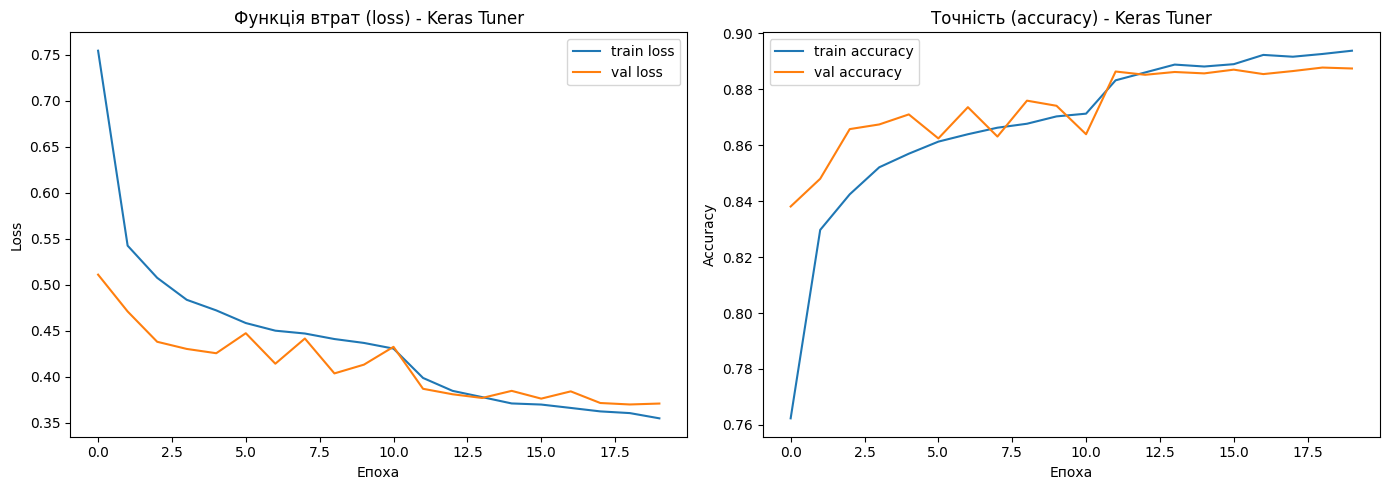

In [17]:
# Оцініть найкращу модель та побудуйте графіки навчання.
# Ваш код:
tuned_test_loss, tuned_test_accuracy = best_model.evaluate(x_test, y_test, verbose=0)
print(f"Tuned model тестова accuracy: {tuned_test_accuracy:.4f}")
print(f"Tuned model тестова loss: {tuned_test_loss:.4f}")
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].plot(tuned_history.history["loss"], label="train loss")
axes[0].plot(tuned_history.history["val_loss"], label="val loss")
axes[0].set_title("Функція втрат (loss) - Keras Tuner")
axes[0].set_xlabel("Епоха")
axes[0].set_ylabel("Loss")
axes[0].legend()
axes[1].plot(tuned_history.history["accuracy"], label="train accuracy")
axes[1].plot(tuned_history.history["val_accuracy"], label="val accuracy")
axes[1].set_title("Точність (accuracy) - Keras Tuner")
axes[1].set_xlabel("Епоха")
axes[1].set_ylabel("Accuracy")
axes[1].legend()
plt.tight_layout()
plt.show()


# Висновки. Порівняння моделей

Порівняйте модель із завдання 1 та модель після автоматизованого налаштування. Результати внесіть до таблиці.

| Показник | Модель із завдання 1 | Модель після Keras Tuner |
|---|---|---|
| Кількість прихованих шарів | 2 | 2 |
| Кількість нейронів | 256, 128 | 416, 32 |
| Швидкість навчання | 0.001 | 0.001 |
| Точність на тестовій вибірці (accuracy) | 0.8933 | 0.8834 |
| Втрати на тестовій вибірці (loss) | 0.3110 | 0.3912 |
| Кількість епох навчання | 30 | 20 |

**У висновках дайте відповідь:**

1. Чи досягнуто точності **не нижче 0,87** у завданні 1?
2. Чи покращила оптимізація гіперпараметрів точність на тестовій вибірці?
3. Які гіперпараметри виявилися найкращими і чому отриманий результат може відрізнятися між запусками?
4. Які класи Fashion MNIST класифікувати найскладніше?

**Власні висновки:**  
Точності не нижче 0.87 у завданні 1 досягнуто (0.8933 на тестовій вибірці), вимогу виконано. Автоматизоване налаштування гіперпараметрів за допомогою Keras Tuner у цьому випадку НЕ покращило точність — модель, знайдена RandomSearch (2 шари, 416 і 32 нейрони, learning_rate 0.001), показала трохи нижчу тестову accuracy (0.8834) порівняно з моделлю з завдання 1 (0.8933), хоча обидві моделі мають однакову кількість прихованих шарів і ту саму швидкість навчання. Це пояснюється тим, що пошук виконувався лише з max_trials=3, а отже охоплено лише малу частину простору гіперпараметрів; крім того, другий шар tuner-моделі має лише 32 нейрони (проти 128 у базовій моделі), що звужує "вузьке місце" мережі перед вихідним шаром, а додана L2-регуляризація також стримує здатність моделі підлаштовуватись під дані. Результат міг би відрізнятися між запусками через випадковість ініціалізації ваг RandomSearch і випадковий підбір комбінацій гіперпараметрів — за більшої кількості спроб (наприклад, max_trials=10-20) ймовірність знайти кращу конфігурацію зростає. Найскладнішим для розпізнавання класом Fashion MNIST в обох моделях залишається Shirt, який часто плутається з T-shirt/top, Pullover і Coat через схожість силуету одягу.